**Objective:** Perform a complete EDA on a synthetic patient health-risk dataset to understand
the data, clean it, and uncover patterns related to **heart disease risk**.

**Dataset:** `healthcare_dataset.csv` (2,025 patient records, 17 columns)

### 1.2 Column Dictionary

| Column | Description |
|---|---|
| patient_id | Unique patient identifier |
| age | Age in years |
| gender | Male / Female (raw data has inconsistent labels) |
| region | Geographic region |
| bmi | Body Mass Index |
| systolic_bp / diastolic_bp | Blood pressure readings (mmHg) |
| cholesterol | Total cholesterol (mg/dL) |
| glucose | Fasting glucose (mg/dL) |
| heart_rate | Resting heart rate (bpm) |
| smoking_status | Never / Former / Current |
| alcohol_consumption | None / Occasional / Regular |
| exercise_level | Low / Moderate / High |
| family_history | Family history of heart disease (Yes/No) |
| annual_income | Annual income (may contain invalid negatives) |
| hospital_visits_last_year | Count of hospital visits |
| heart_disease | **Target** — Yes/No |




## Project Roadmap
1. [Data Understanding](#1)
2. [Statistical analysis](#2)
3. [Data Cleaning](#3)
4. [Univariate Analysis](#4)
5. [Bivariate Analysis](#5)
6. [Multivariate Analysis](#6)
7. [Outlier Analysis (Deep Dive)](#7)
8. [Key Insights & Conclusion](#8)
---

1. [Data Understanding](#1)

In [1]:
# importting liabrares which was essential

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [3]:
df=pd.read_csv(r"healthcare_dataset.csv")

df.head()

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,alcohol_consumption,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,P101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,NaN,Moderate,No,37000.0,1,No
1,P100140,88.0,Male,East,28.4,155.0,94.0,262.0,128.0,67.0,Never,NaN,Moderate,No,21000.0,8,Yes
2,P100110,37.0,Male,West,28.4,134.0,91.0,204.0,118.0,83.0,Former,NaN,Moderate,No,46000.0,2,Yes
3,P100638,75.0,Male,North,18.1,152.0,79.0,214.0,108.0,52.0,Current,NaN,Low,No,25300.0,5,Yes
4,P100702,30.0,Male,North,27.3,149.0,99.0,199.0,115.0,80.0,Former,Occasional,Low,Yes,65200.0,3,Yes


In [3]:
df.tail()

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,alcohol_consumption,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
2020,P101603,40.0,Female,North,23.8,145.000000,81.0,242.0,98.0,73.0,Current,Occasional,High,Yes,43400.0,1,Yes
2021,P100502,87.0,Male,West,30.7,160.000000,96.0,246.0,121.0,76.0,Never,NaN,Low,No,NaN,2,Yes
2022,P100537,26.0,Female,West,21.7,125.000000,95.0,176.0,95.0,74.0,Never,NaN,Moderate,Yes,24200.0,3,Yes
2023,P101220,64.0,Male,North,31.2,150.000000,97.0,237.0,118.0,68.0,Former,Occasional,Moderate,No,53600.0,2,Yes
2024,P100175,51.0,Female,North,16.8,230.766341,83.0,223.0,99.0,76.0,Former,NaN,Moderate,No,42100.0,1,No


In [4]:
df.shape

(2025, 17)

In [5]:
df.shape[0]

2025

In [6]:
df.shape[1]

17

In [5]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,alcohol_consumption,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,P101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,NaN,Moderate,No,37000.0,1,No


In [7]:
df.annual_income.value_counts()

annual_income
34100.0     10
41000.0     10
37800.0     10
32700.0      9
27800.0      9
            ..
36500.0      1
59800.0      1
18200.0      1
39300.0      1
118800.0     1
Name: count, Length: 696, dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 2025 non-null   str    
 1   age                        2025 non-null   float64
 2   gender                     2025 non-null   str    
 3   region                     2025 non-null   str    
 4   bmi                        1943 non-null   float64
 5   systolic_bp                2025 non-null   float64
 6   diastolic_bp               1965 non-null   float64
 7   cholesterol                1904 non-null   float64
 8   glucose                    1923 non-null   float64
 9   heart_rate                 2025 non-null   float64
 10  smoking_status             2025 non-null   str    
 11  alcohol_consumption        1211 non-null   str    
 12  exercise_level             1965 non-null   str    
 13  family_history             2025 non-null   str    
 14  ann

# Data insights:


patiendid: it is integer , but disclosed as string and in patiendid we have exact value "P"

BMI : It has null values 

diastolic_bp : it has also null values

cholesterol : it has null values

glucose    ; it has null valures


heart_rate : it wrong data , we have to set as integer


  alcohol_consumption :  it has null values


  exercise_level  : it has null values


  annual_income   : convert into integer

2. [Statistical analysis](#2)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2025.0,53.779423,21.048602,18.0,35.0,54.0,72.00,108.017232
bmi,1943.0,26.307874,4.760546,14.0,23.0,26.1,29.35,44.200000
systolic_bp,2025.0,144.104620,14.112953,103.0,135.0,144.0,152.00,258.041051
diastolic_bp,1965.0,86.173028,7.255701,62.0,81.0,86.0,91.00,110.000000
cholesterol,1904.0,216.598407,33.587026,148.0,198.0,214.0,232.00,487.924410
glucose,1923.0,118.570463,14.405478,62.0,109.0,118.0,128.00,168.000000
heart_rate,2025.0,71.190617,8.990235,41.0,65.0,71.0,77.00,99.000000
annual_income,1862.0,41985.392052,22887.161266,-57600.0,26600.0,37300.0,51000.00,191700.000000
hospital_visits_last_year,2025.0,3.318025,1.877839,0.0,2.0,3.0,5.00,11.000000


- Data insights:

 Annual_income may be outlier

In [9]:
df.describe(include="object").T

,count,unique,top,freq
patient_id,2025,2000,P101926,2
gender,2025,8,Female,1008
region,2025,4,North,594
smoking_status,2025,3,Never,1120
alcohol_consumption,1211,2,Occasional,865
exercise_level,1965,3,Moderate,906
family_history,2025,2,No,1371
heart_disease,2025,2,Yes,1495


In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,2025,2000,P101926,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2025.0,NaN,NaN,NaN,53.779423,21.048602,18.0,35.0,54.0,72.0,108.017232
gender,2025,8,Female,1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2025,4,North,594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1943.0,NaN,NaN,NaN,26.307874,4.760546,14.0,23.0,26.1,29.35,44.2
systolic_bp,2025.0,NaN,NaN,NaN,144.10462,14.112953,103.0,135.0,144.0,152.0,258.041051
diastolic_bp,1965.0,NaN,NaN,NaN,86.173028,7.255701,62.0,81.0,86.0,91.0,110.0
cholesterol,1904.0,NaN,NaN,NaN,216.598407,33.587026,148.0,198.0,214.0,232.0,487.92441
glucose,1923.0,NaN,NaN,NaN,118.570463,14.405478,62.0,109.0,118.0,128.0,168.0
heart_rate,2025.0,NaN,NaN,NaN,71.190617,8.990235,41.0,65.0,71.0,77.0,99.0


# - Data cleaning

In [11]:
df.dtypes

patient_id                       str
age                          float64
gender                           str
region                           str
bmi                          float64
systolic_bp                  float64
diastolic_bp                 float64
cholesterol                  float64
glucose                      float64
heart_rate                   float64
smoking_status                   str
alcohol_consumption              str
exercise_level                   str
family_history                   str
annual_income                float64
hospital_visits_last_year      int64
heart_disease                    str
dtype: object

In [12]:
df.head()

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,alcohol_consumption,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,P101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,NaN,Moderate,No,37000.0,1,No
1,P100140,88.0,Male,East,28.4,155.0,94.0,262.0,128.0,67.0,Never,NaN,Moderate,No,21000.0,8,Yes
2,P100110,37.0,Male,West,28.4,134.0,91.0,204.0,118.0,83.0,Former,NaN,Moderate,No,46000.0,2,Yes
3,P100638,75.0,Male,North,18.1,152.0,79.0,214.0,108.0,52.0,Current,NaN,Low,No,25300.0,5,Yes
4,P100702,30.0,Male,North,27.3,149.0,99.0,199.0,115.0,80.0,Former,Occasional,Low,Yes,65200.0,3,Yes


In [ ]:
df["patient_id"]=df["patient_id"].str.replace("P",'')

In [15]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,alcohol_consumption,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,NaN,Moderate,No,37000.0,1,No


In [16]:
df.dtypes

patient_id                       str
age                          float64
gender                           str
region                           str
bmi                          float64
systolic_bp                  float64
diastolic_bp                 float64
cholesterol                  float64
glucose                      float64
heart_rate                   float64
smoking_status                   str
alcohol_consumption              str
exercise_level                   str
family_history                   str
annual_income                float64
hospital_visits_last_year      int64
heart_disease                    str
dtype: object

In [19]:
df["patient_id"]=df["patient_id"].astype("int")

In [20]:
df.dtypes

patient_id                     int64
age                          float64
gender                           str
region                           str
bmi                          float64
systolic_bp                  float64
diastolic_bp                 float64
cholesterol                  float64
glucose                      float64
heart_rate                   float64
smoking_status                   str
alcohol_consumption              str
exercise_level                   str
family_history                   str
annual_income                float64
hospital_visits_last_year      int64
heart_disease                    str
dtype: object

In [16]:
df["age"].value_counts()

age
79.000000     41
29.000000     39
87.000000     39
35.000000     38
24.000000     37
              ..
105.377509     1
108.017232     1
98.695142      1
98.023167      1
107.812490     1
Name: count, Length: 80, dtype: int64

- finding duplicate the values

In [17]:
df.duplicated().sum()

np.int64(24)

- removing duplicates

In [18]:
df.drop_duplicates(inplace=True)

In [19]:
# checking data shape

df.shape

(2001, 17)

- finding null values

In [20]:
df.isnull()

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,alcohol_consumption,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2021,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False
2022,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
2023,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [21]:
df.isnull().sum()

patient_id                     0
age                            0
gender                         0
region                         0
bmi                           80
systolic_bp                    0
diastolic_bp                  60
cholesterol                  119
glucose                      100
heart_rate                     0
smoking_status                 0
alcohol_consumption          797
exercise_level                60
family_history                 0
annual_income                160
hospital_visits_last_year      0
heart_disease                  0
dtype: int64

In [22]:
# if null values more than 25% values , i was removed that column
df.isnull().sum()/df.shape[0]*100

patient_id                    0.000000
age                           0.000000
gender                        0.000000
region                        0.000000
bmi                           3.998001
systolic_bp                   0.000000
diastolic_bp                  2.998501
cholesterol                   5.947026
glucose                       4.997501
heart_rate                    0.000000
smoking_status                0.000000
alcohol_consumption          39.830085
exercise_level                2.998501
family_history                0.000000
annual_income                 7.996002
hospital_visits_last_year     0.000000
heart_disease                 0.000000
dtype: float64

In [23]:

df.drop(columns=["alcohol_consumption"],inplace=True)

In [24]:
df.columns

Index(['patient_id', 'age', 'gender', 'region', 'bmi', 'systolic_bp',
       'diastolic_bp', 'cholesterol', 'glucose', 'heart_rate',
       'smoking_status', 'exercise_level', 'family_history', 'annual_income',
       'hospital_visits_last_year', 'heart_disease'],
      dtype='str')

# - filling null/missing values rules

- mean  : if don't have outliers
- median : if we have outliers
- mode : filling text column , with most repeated value

In [25]:
df["bmi"]=df["bmi"].fillna(df["bmi"].mean())

In [26]:
df['diastolic_bp']=df['diastolic_bp'].fillna(df['diastolic_bp'].mean())

In [27]:
df["cholesterol"]=df["cholesterol"].fillna(df['cholesterol'].mean())

In [28]:
df.glucose = df.glucose.fillna(df.glucose.mean())

In [29]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No


In [ ]:
df.exercise_level = df.exercise_level.fillna(df.exercise_level.mode()[0])

In [31]:
df.annual_income=df.annual_income.fillna(df.annual_income.median())

In [32]:
df.isnull().sum()

patient_id                   0
age                          0
gender                       0
region                       0
bmi                          0
systolic_bp                  0
diastolic_bp                 0
cholesterol                  0
glucose                      0
heart_rate                   0
smoking_status               0
exercise_level               0
family_history               0
annual_income                0
hospital_visits_last_year    0
heart_disease                0
dtype: int64

In [33]:
df.gender.value_counts()

gender
Female    995
Male      966
F           8
male        8
FEMALE      7
MALE        7
female      7
M           3
Name: count, dtype: int64

In [34]:
print("Before:", df['gender'].unique())

Before: <StringArray>
['Female', 'Male', 'FEMALE', 'MALE', 'female', 'M', 'F', 'male']
Length: 8, dtype: str


In [35]:


gender_map = {
    'M': 'Male', 'male': 'Male', 'MALE': 'Male',
    'F': 'Female', 'female': 'Female', 'FEMALE': 'Female'
}
df['gender'] = df['gender'].replace(gender_map)

print("After:", df['gender'].unique())

After: <StringArray>
['Female', 'Male']
Length: 2, dtype: str


In [36]:
df.gender.value_counts()

gender
Female    1017
Male       984
Name: count, dtype: int64

- EDA: Explorataory Data analysis

Data visulization

- Univariate Analysis:

analying of one variable or one column at a time is called univariate analysis


- Bi variate analysis:

analying of two  variable or two  column at a time is called bivariate analysis


- Multivariate Analysis:
 
 analying of morethan two   variable or two  column at a time is called multi variate analysis

In [37]:
df.dtypes

patient_id                     int64
age                          float64
gender                           str
region                           str
bmi                          float64
systolic_bp                  float64
diastolic_bp                 float64
cholesterol                  float64
glucose                      float64
heart_rate                   float64
smoking_status                   str
exercise_level                   str
family_history                   str
annual_income                float64
hospital_visits_last_year      int64
heart_disease                    str
dtype: object

In [38]:
# Numerical columns
numeric_features = df.select_dtypes(include=['number']).columns.tolist()

# Categorical columns
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Print columns
print("We have {} numerical features: {}".format(len(numeric_features), numeric_features))


print("\nWe have {} categorical features: {}".format(len(categorical_features), categorical_features))

We have 10 numerical features: ['patient_id', 'age', 'bmi', 'systolic_bp', 'diastolic_bp', 'cholesterol', 'glucose', 'heart_rate', 'annual_income', 'hospital_visits_last_year']

We have 6 categorical features: ['gender', 'region', 'smoking_status', 'exercise_level', 'family_history', 'heart_disease']


- Univariate analysis

    - numerical columns


 patient_id
********************
count      2001.000000
mean     100999.115942
std         577.605747
min      100000.000000
25%      100499.000000
50%      100999.000000
75%      101499.000000
max      101999.000000
Name: patient_id, dtype: float64


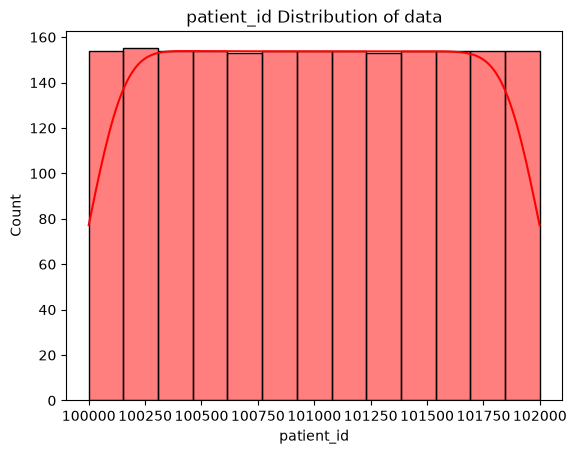


 age
********************
count    2001.000000
mean       53.731468
std        21.066002
min        18.000000
25%        35.000000
50%        54.000000
75%        72.000000
max       108.017232
Name: age, dtype: float64


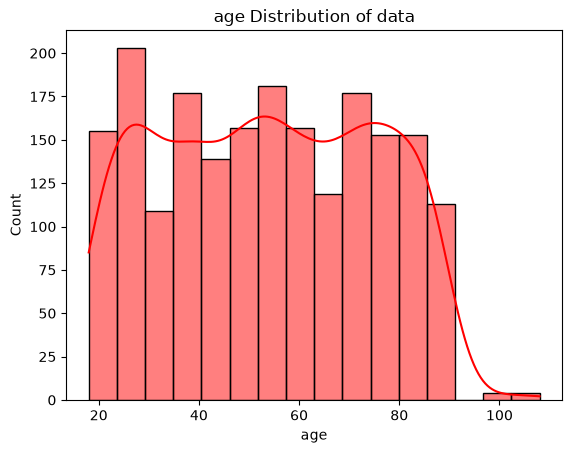


 bmi
********************
count    2001.000000
mean       26.309006
std         4.655843
min        14.000000
25%        23.200000
50%        26.309006
75%        29.200000
max        44.200000
Name: bmi, dtype: float64


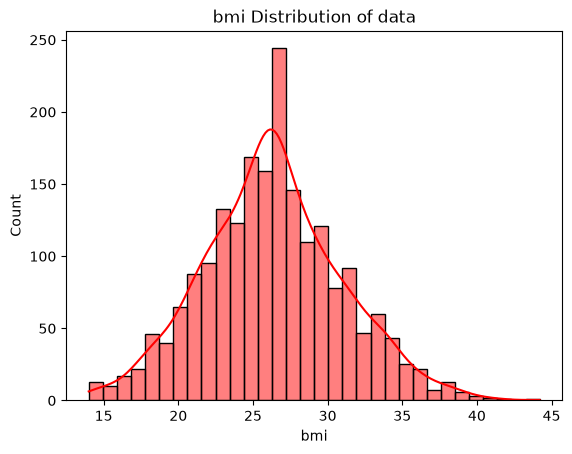


 systolic_bp
********************
count    2001.000000
mean      144.124366
std        14.129779
min       103.000000
25%       135.000000
50%       144.000000
75%       152.000000
max       258.041051
Name: systolic_bp, dtype: float64


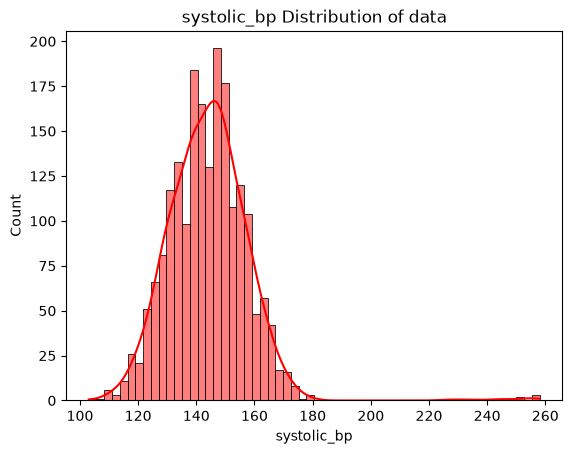


 diastolic_bp
********************
count    2001.000000
mean       86.178259
std         7.152074
min        62.000000
25%        81.000000
50%        86.000000
75%        91.000000
max       110.000000
Name: diastolic_bp, dtype: float64


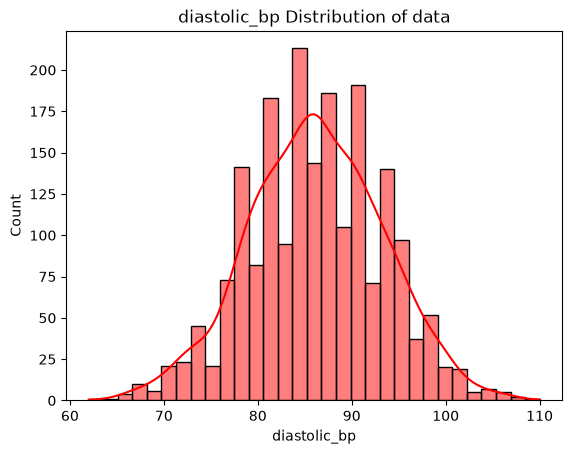


 cholesterol
********************
count    2001.000000
mean      216.317008
std        31.805239
min       148.000000
25%       199.000000
50%       216.317008
75%       231.000000
max       487.924410
Name: cholesterol, dtype: float64


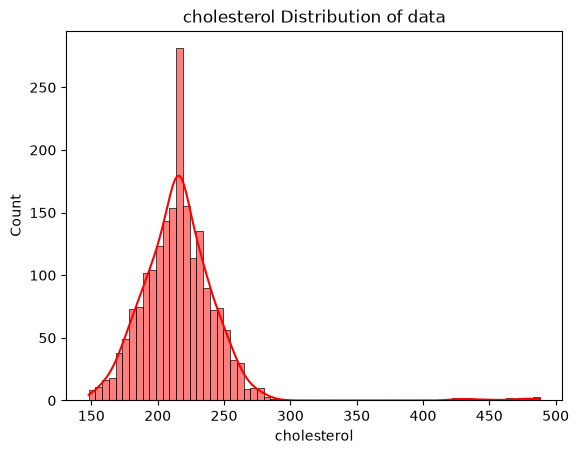


 glucose
********************
count    2001.000000
mean      118.578643
std        14.049119
min        62.000000
25%       109.000000
50%       118.578643
75%       128.000000
max       168.000000
Name: glucose, dtype: float64


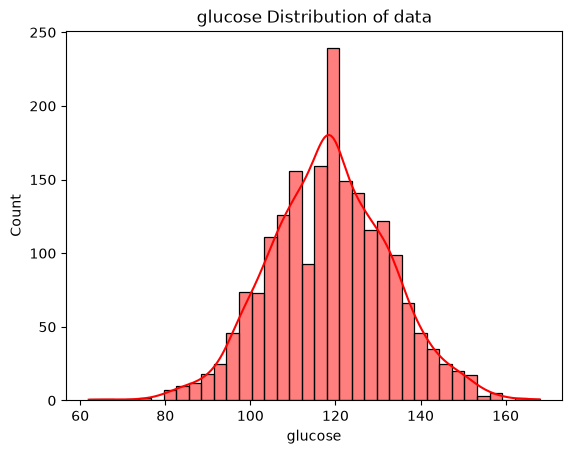


 heart_rate
********************
count    2001.000000
mean       71.175412
std         9.005316
min        41.000000
25%        65.000000
50%        71.000000
75%        77.000000
max        99.000000
Name: heart_rate, dtype: float64


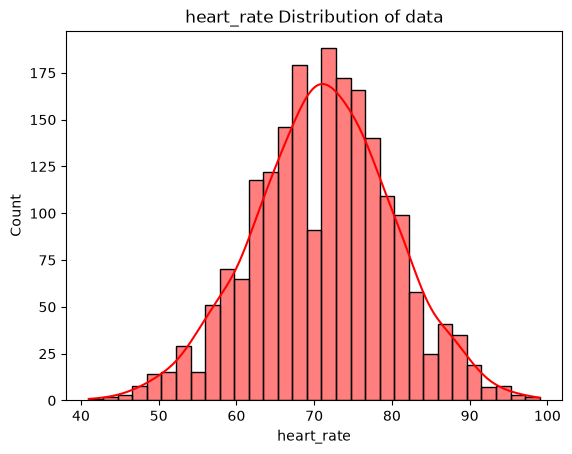


 annual_income
********************
count      2001.000000
mean      41575.012494
std       21947.658994
min      -57600.000000
25%       27400.000000
50%       37300.000000
75%       49300.000000
max      191700.000000
Name: annual_income, dtype: float64


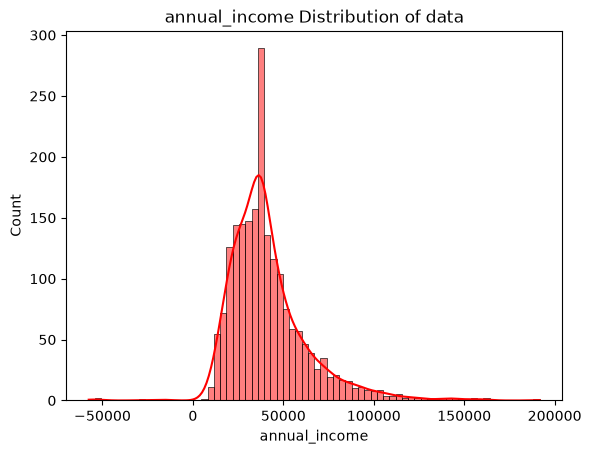


 hospital_visits_last_year
********************
count    2001.000000
mean        3.315342
std         1.879364
min         0.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        11.000000
Name: hospital_visits_last_year, dtype: float64


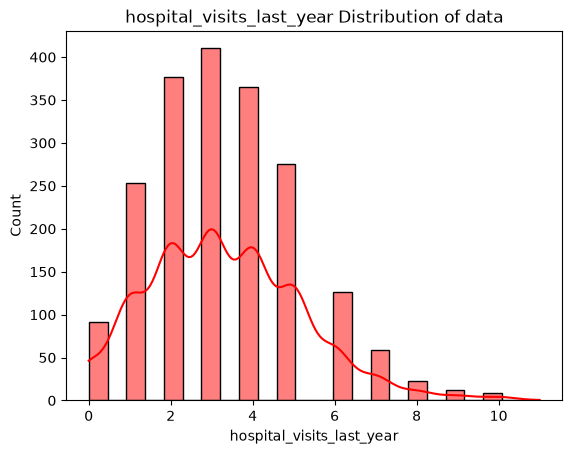

In [39]:
for col in numeric_features:
    
    print("\n",col)
    print("********************")
    print(df[col].describe())


    sns.histplot(df[col],kde=True,color="red")
    plt.title(f"{col} Distribution of data")
    plt.show()

In [40]:
import math

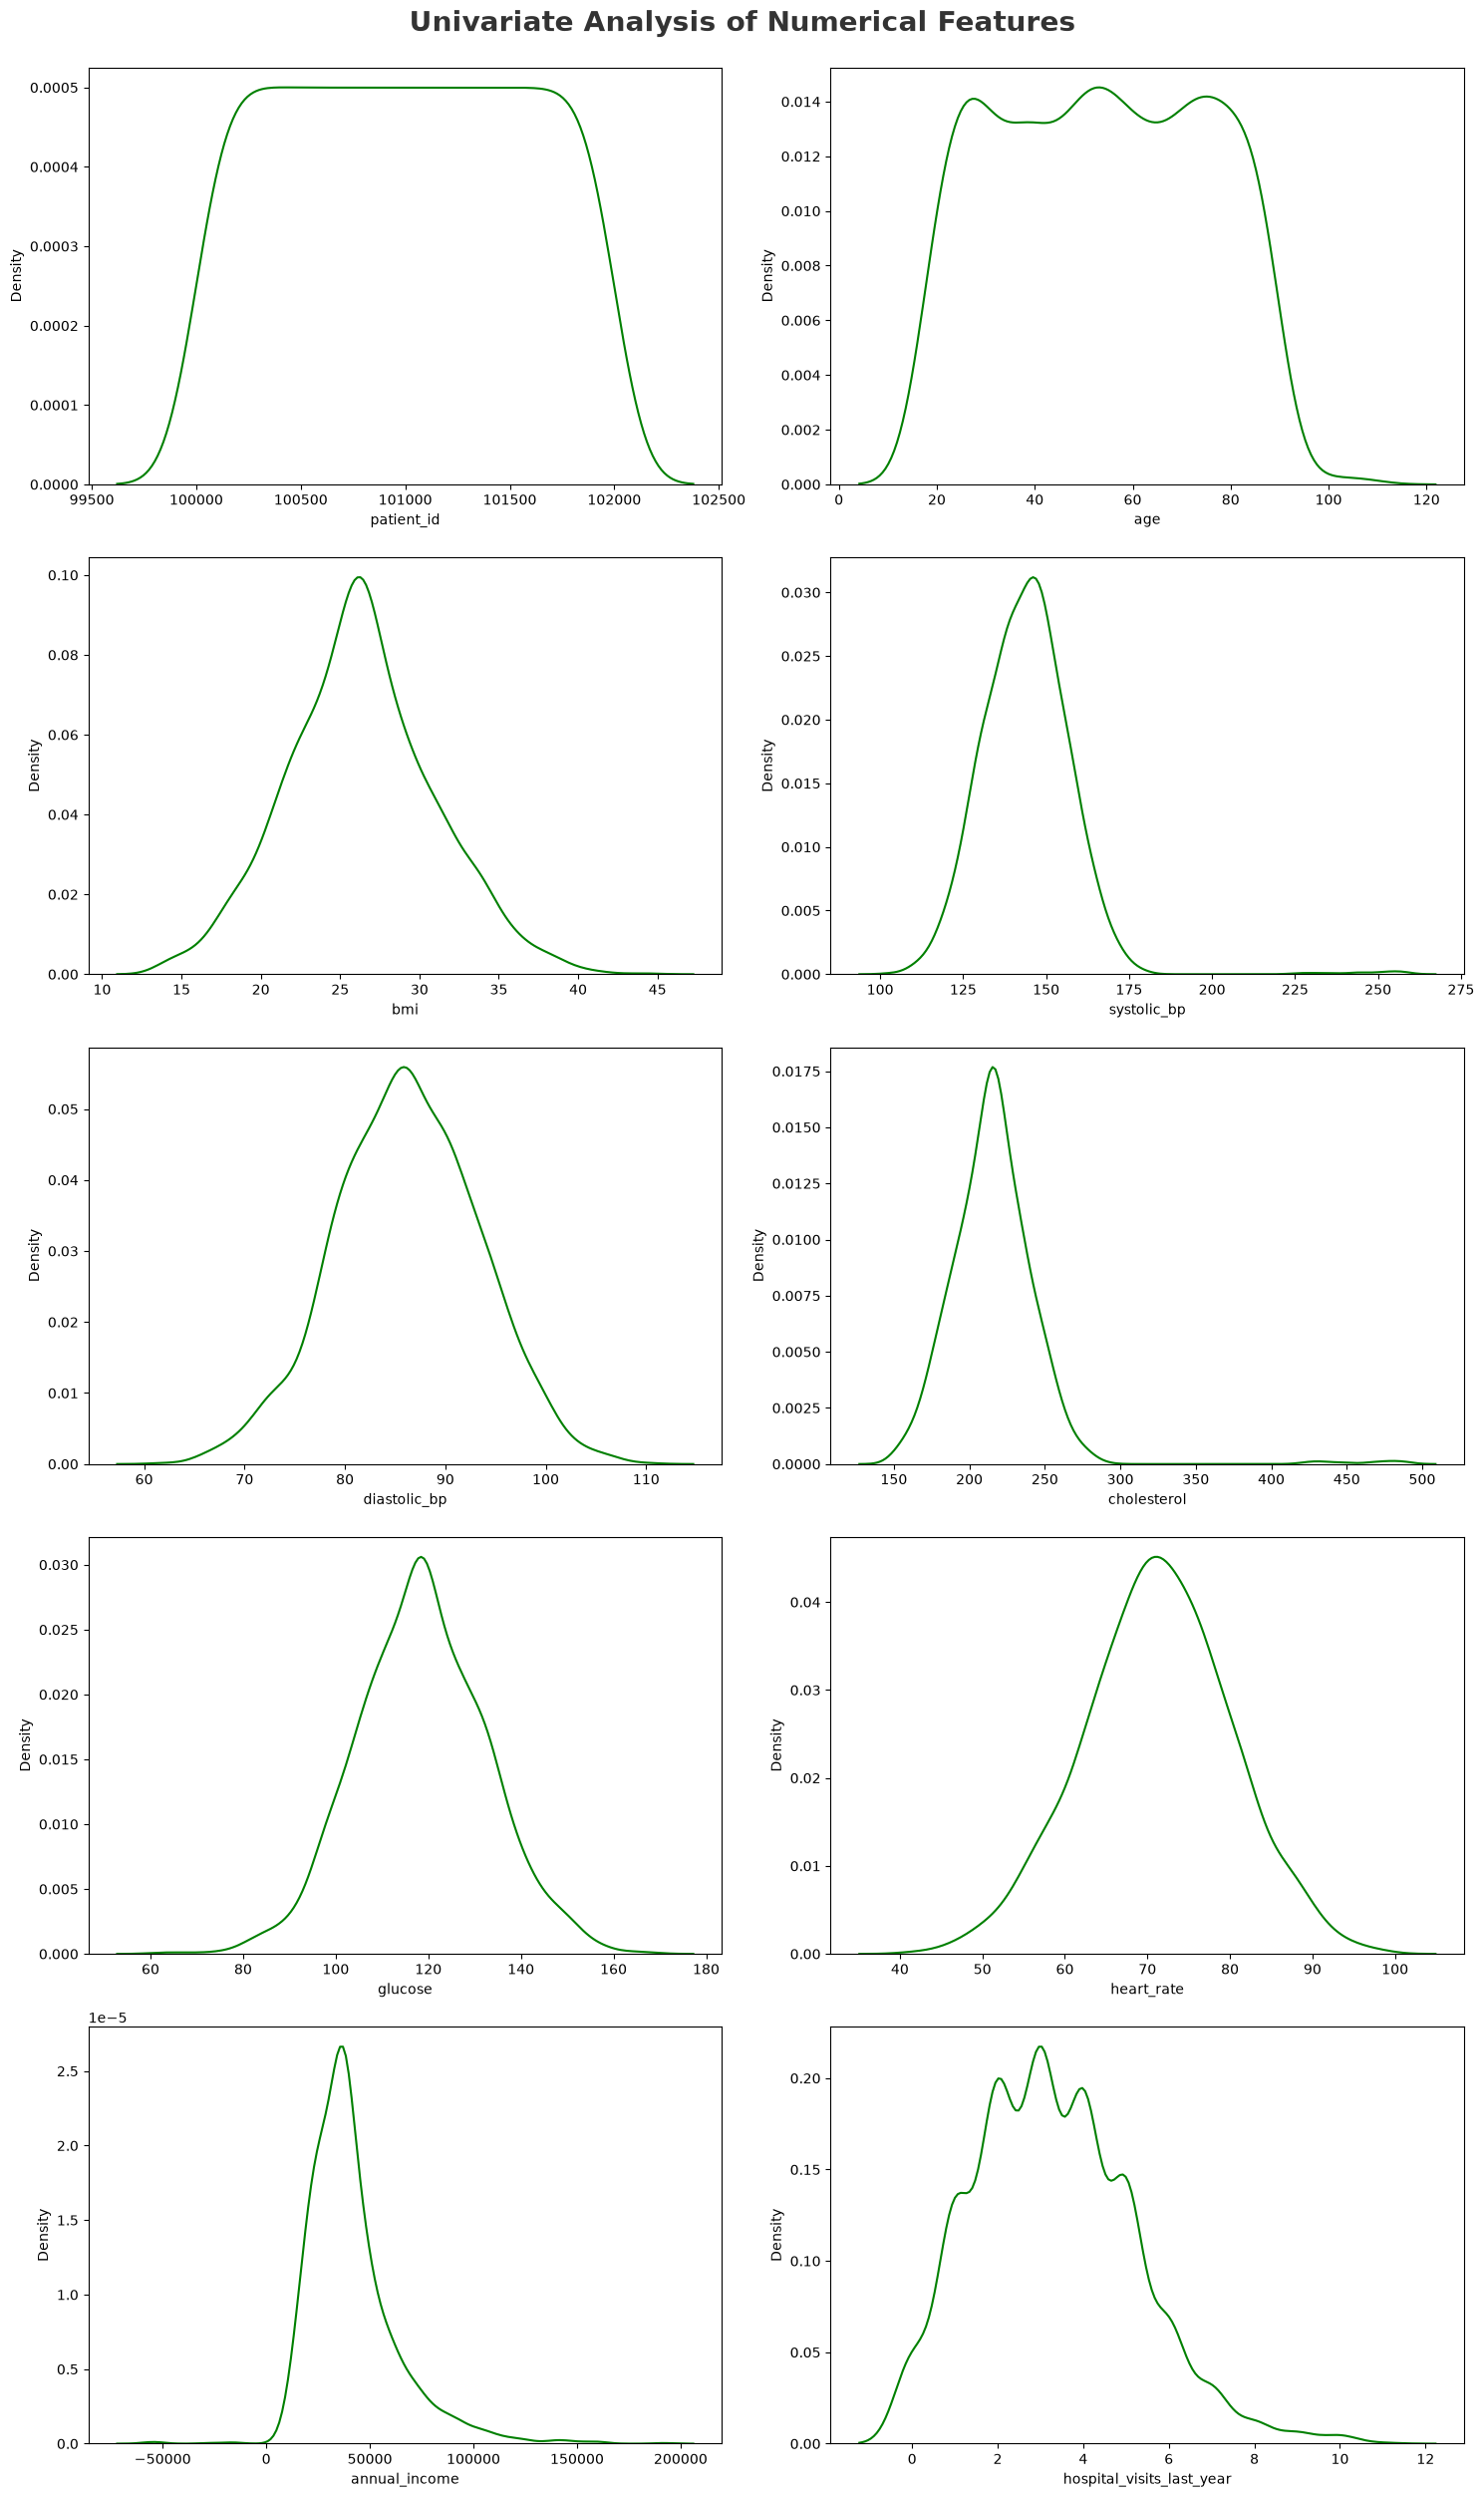

In [41]:
# Calculate the number of rows and columns based on the number of features
n_features = len(numeric_features)
n_cols = 2  # You can adjust this as needed (e.g., 2 columns for 6 features)
n_rows = int(np.ceil(n_features / n_cols))  # Calculate rows to fit all features

# Create the plot
plt.figure(figsize=(15, 5 * n_rows))
plt.suptitle('Univariate Analysis of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

# Loop to create subplots for each numerical feature
for i in range(n_features):
    plt.subplot(n_rows, n_cols, i+1)  # Dynamically set subplot grid
    sns.kdeplot(x=df[numeric_features[i]], color='green')
    plt.xlabel(numeric_features[i])

plt.tight_layout()
plt.show()

In [42]:
numeric_features

['patient_id',
 'age',
 'bmi',
 'systolic_bp',
 'diastolic_bp',
 'cholesterol',
 'glucose',
 'heart_rate',
 'annual_income',
 'hospital_visits_last_year']

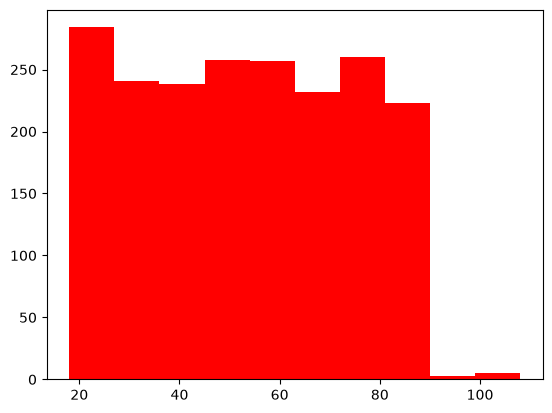

In [43]:
plt.hist(df['age'], bins=10,color="red")
plt.show()

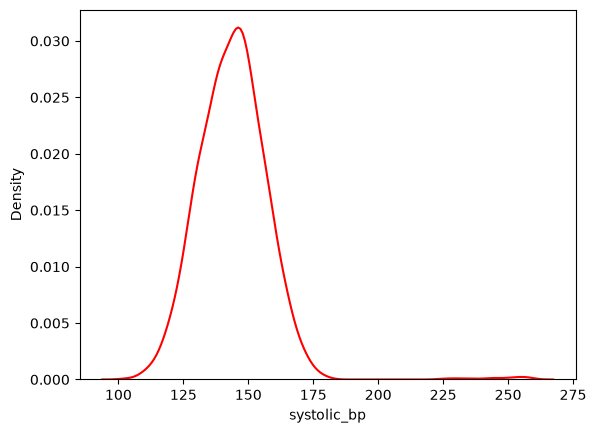

In [44]:
sns.kdeplot(df["systolic_bp"],color="red")
plt.show()

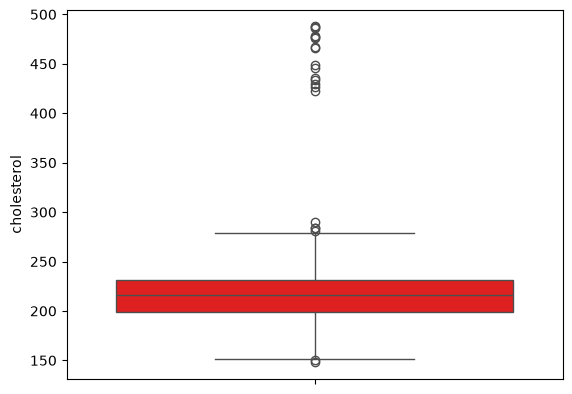

In [45]:
sns.boxplot(df.cholesterol,color="red")
plt.show()

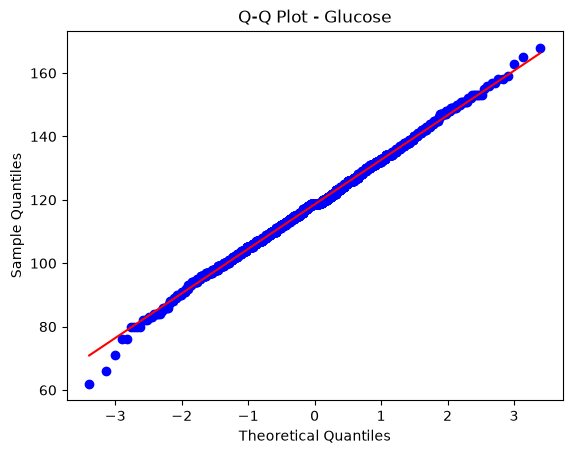

In [46]:
import scipy.stats as stats

stats.probplot(df.glucose, dist="norm", plot=plt)

plt.title('Q-Q Plot - Glucose')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.show()

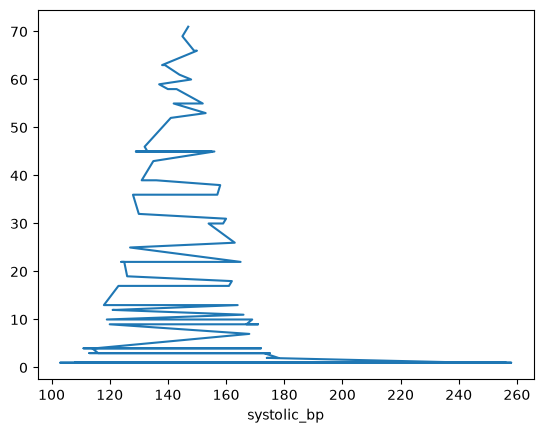

In [47]:
df['systolic_bp'].value_counts().plot(kind="line")
plt.show()

- analysis of categorical data


 gender
********************
count       2001
unique         2
top       Female
freq        1017
Name: gender, dtype: object


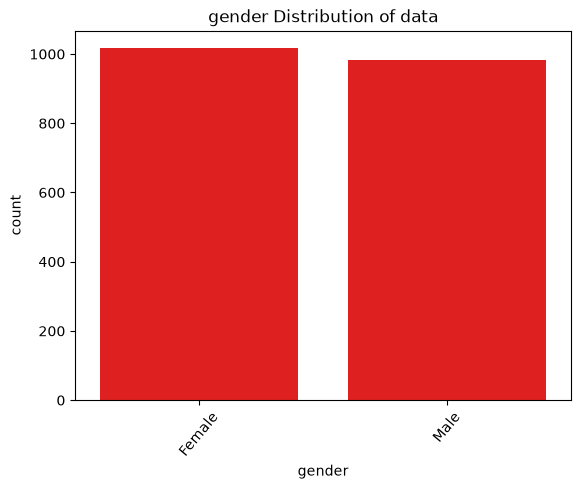


 region
********************
count      2001
unique        4
top       North
freq        587
Name: region, dtype: object


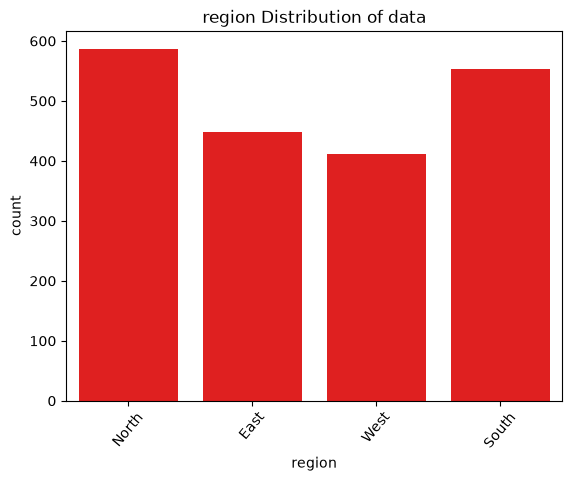


 smoking_status
********************
count      2001
unique        3
top       Never
freq       1105
Name: smoking_status, dtype: object


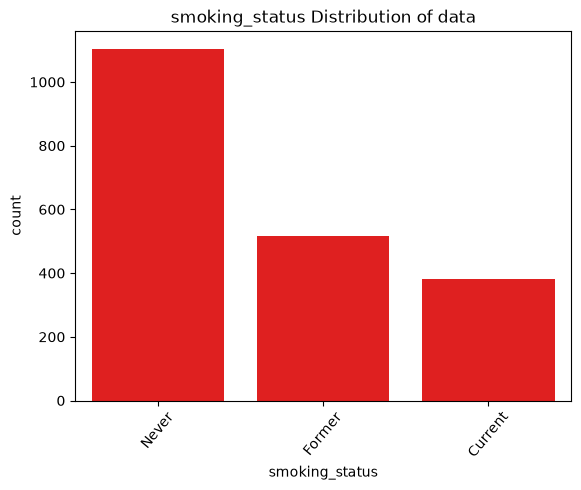


 exercise_level
********************
count         2001
unique           3
top       Moderate
freq           956
Name: exercise_level, dtype: object


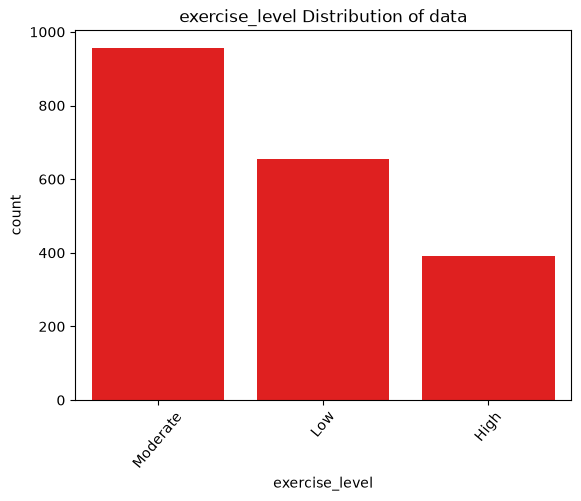


 family_history
********************
count     2001
unique       2
top         No
freq      1353
Name: family_history, dtype: object


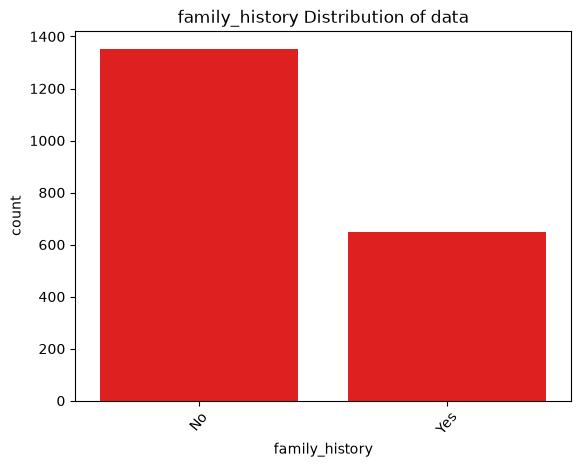


 heart_disease
********************
count     2001
unique       2
top        Yes
freq      1477
Name: heart_disease, dtype: object


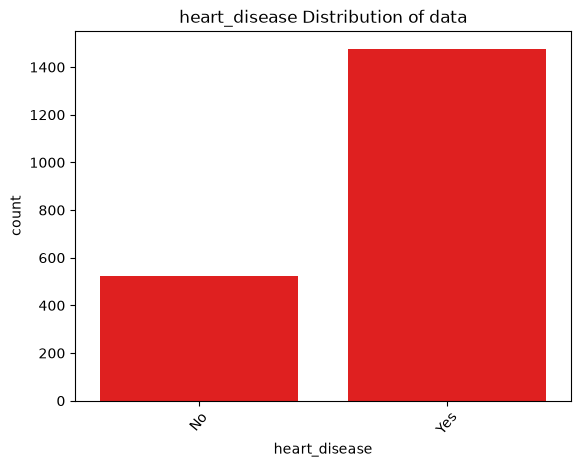

In [48]:
for col in categorical_features:
    
    print("\n",col)
    print("********************")
    print(df[col].describe())


    sns.countplot(x=df[col],color="red")
    plt.title(f"{col} Distribution of data")
    plt.xticks(rotation=50)
    plt.show()

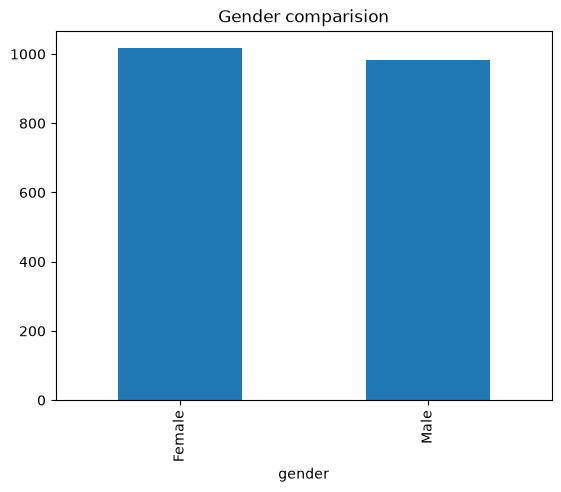

In [49]:
df['gender'].value_counts().plot(kind='bar')
plt.title("Gender comparision")
plt.show()

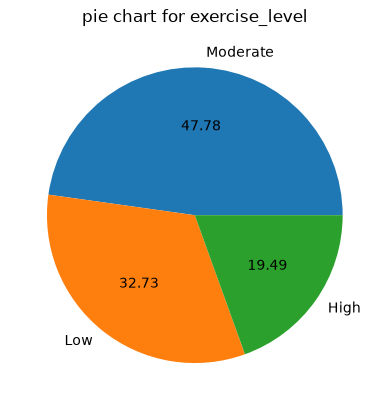

In [50]:
df['exercise_level'].value_counts().plot(kind='pie', autopct='%.2f')
plt.title("pie chart for exercise_level")
plt.show()

In [51]:
df.family_history.value_counts()

family_history
No     1353
Yes     648
Name: count, dtype: int64

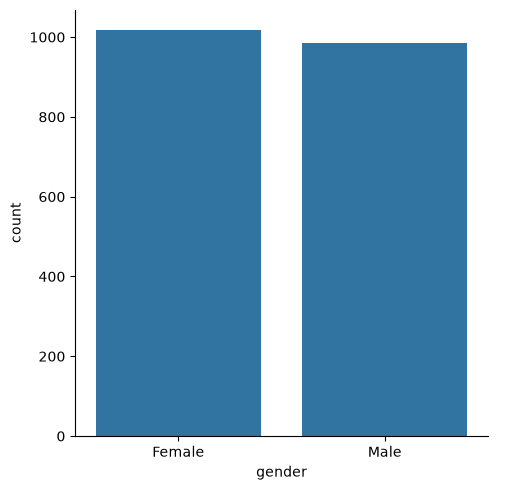

In [52]:
sns.catplot(
    data=df,
    x="gender",
    kind="count"
)

In [53]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No


- Bi variate analysis

- Scatter plot

<Axes: xlabel='age', ylabel='bmi'>

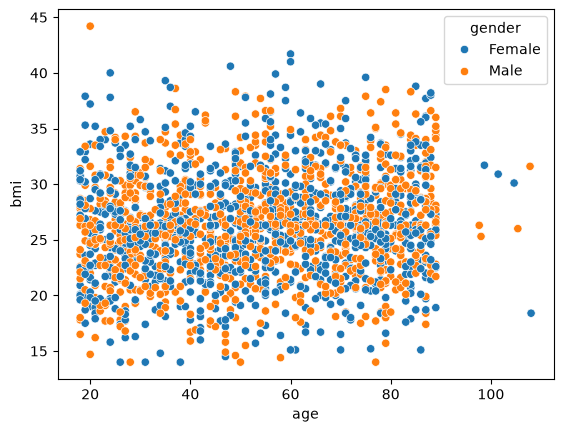

In [54]:
sns.scatterplot(x=df['age'], y=df['bmi'],hue=df["gender"])

<Axes: xlabel='age', ylabel='cholesterol'>

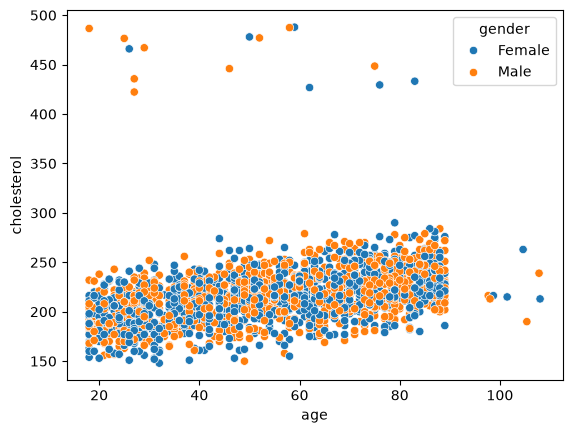

In [55]:
sns.scatterplot(x=df['age'], y=df['cholesterol'],hue=df["gender"])

<Axes: xlabel='glucose', ylabel='age'>

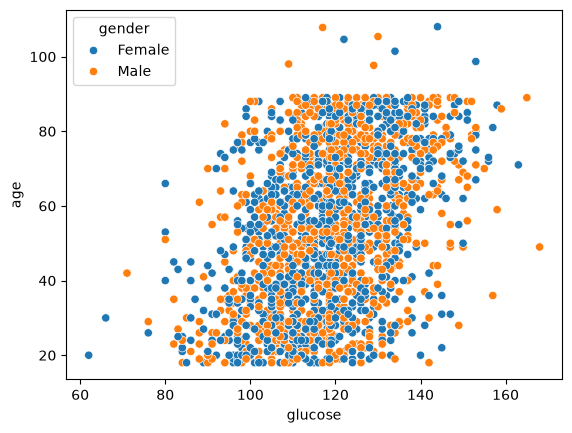

In [56]:
sns.scatterplot(y=df['age'], x=df['glucose'],hue=df["gender"])

- bar graph (cat-num)

<Axes: xlabel='heart_disease', ylabel='age'>

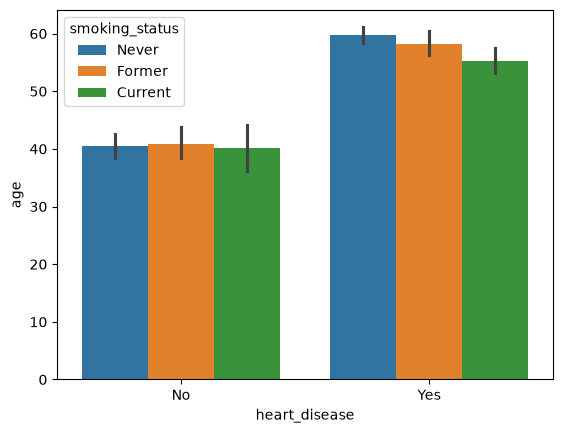

In [57]:
sns.barplot(y=df['age'], x=df['heart_disease'],hue=df["smoking_status"])

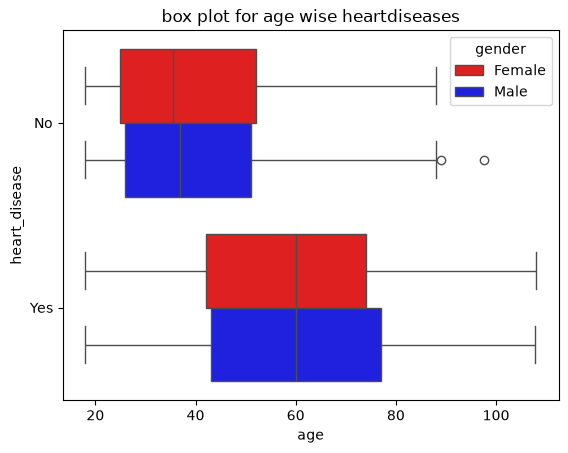

In [58]:
sns.boxplot(x=df['age'], y=df['heart_disease'], hue=df['gender'], palette=["red", "blue"])

plt.title("box plot for age wise heartdiseases")
plt.show()

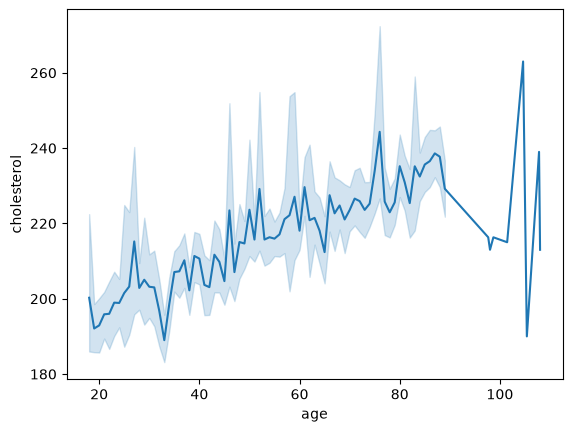

In [59]:
sns.lineplot(x=df["age"],y=df["cholesterol"],palette=["#31B824", "#FF0000"])

plt.show()

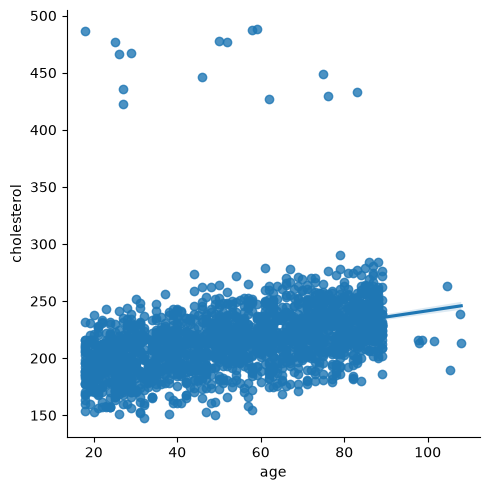

In [60]:
sns.lmplot(x="age",y="cholesterol",data=df) 

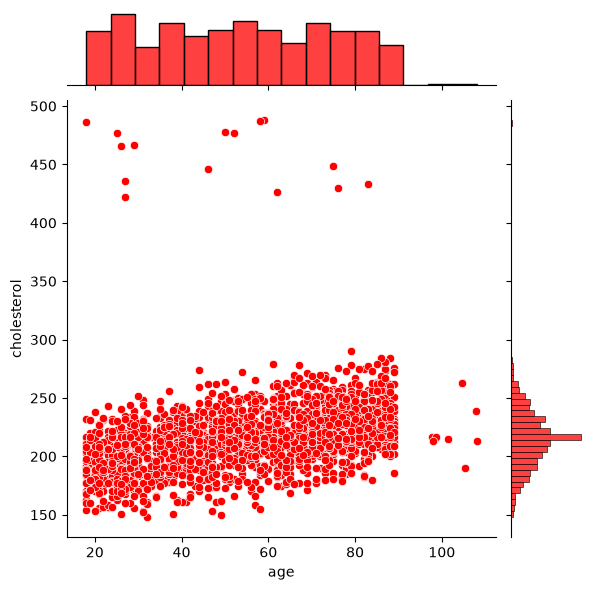

In [61]:
sns.jointplot(x=df["age"],y=df["cholesterol"],color="red")

In [62]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease
0,101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No


In [63]:
df["age"].value_counts().sort_index()

age
18.000000     31
19.000000     26
20.000000     25
21.000000     31
22.000000     22
              ..
101.447333     1
104.629339     1
105.377509     1
107.812490     1
108.017232     1
Name: count, Length: 80, dtype: int64

In [64]:
# Age groups
df['age_group'] = pd.cut(df['age'], bins=[0, 30, 45, 60, 75, 120],
                          labels=['18-30', '31-45', '46-60', '61-75', '76+'])

# BMI category (WHO standard bands)
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 25, 30, 100],
                             labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# Blood pressure category (simplified clinical bands)
def bp_category(row):
    if row['systolic_bp'] < 120 and row['diastolic_bp'] < 80:
        return 'Normal'
    elif row['systolic_bp'] < 130:
        return 'Elevated'
    elif row['systolic_bp'] < 140:
        return 'Hypertension Stage 1'
    else:
        return 'Hypertension Stage 2'

df['bp_category'] = df.apply(bp_category, axis=1)

# Binary flag for convenience in numeric correlations
df['heart_disease_flag'] = (df['heart_disease'] == 'Yes').astype(int)

df[['age_group', 'bmi_category', 'bp_category', 'heart_disease_flag']].head()


,age_group,bmi_category,bp_category,heart_disease_flag
0,46-60,Underweight,Hypertension Stage 1,0
1,76+,Overweight,Hypertension Stage 2,1
2,31-45,Overweight,Hypertension Stage 1,1
3,61-75,Underweight,Hypertension Stage 2,1
4,18-30,Overweight,Hypertension Stage 2,1


In [65]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease,age_group,bmi_category,bp_category,heart_disease_flag
0,101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No,46-60,Underweight,Hypertension Stage 1,0


- categorical data distribution( this is univariate analysis only 

)

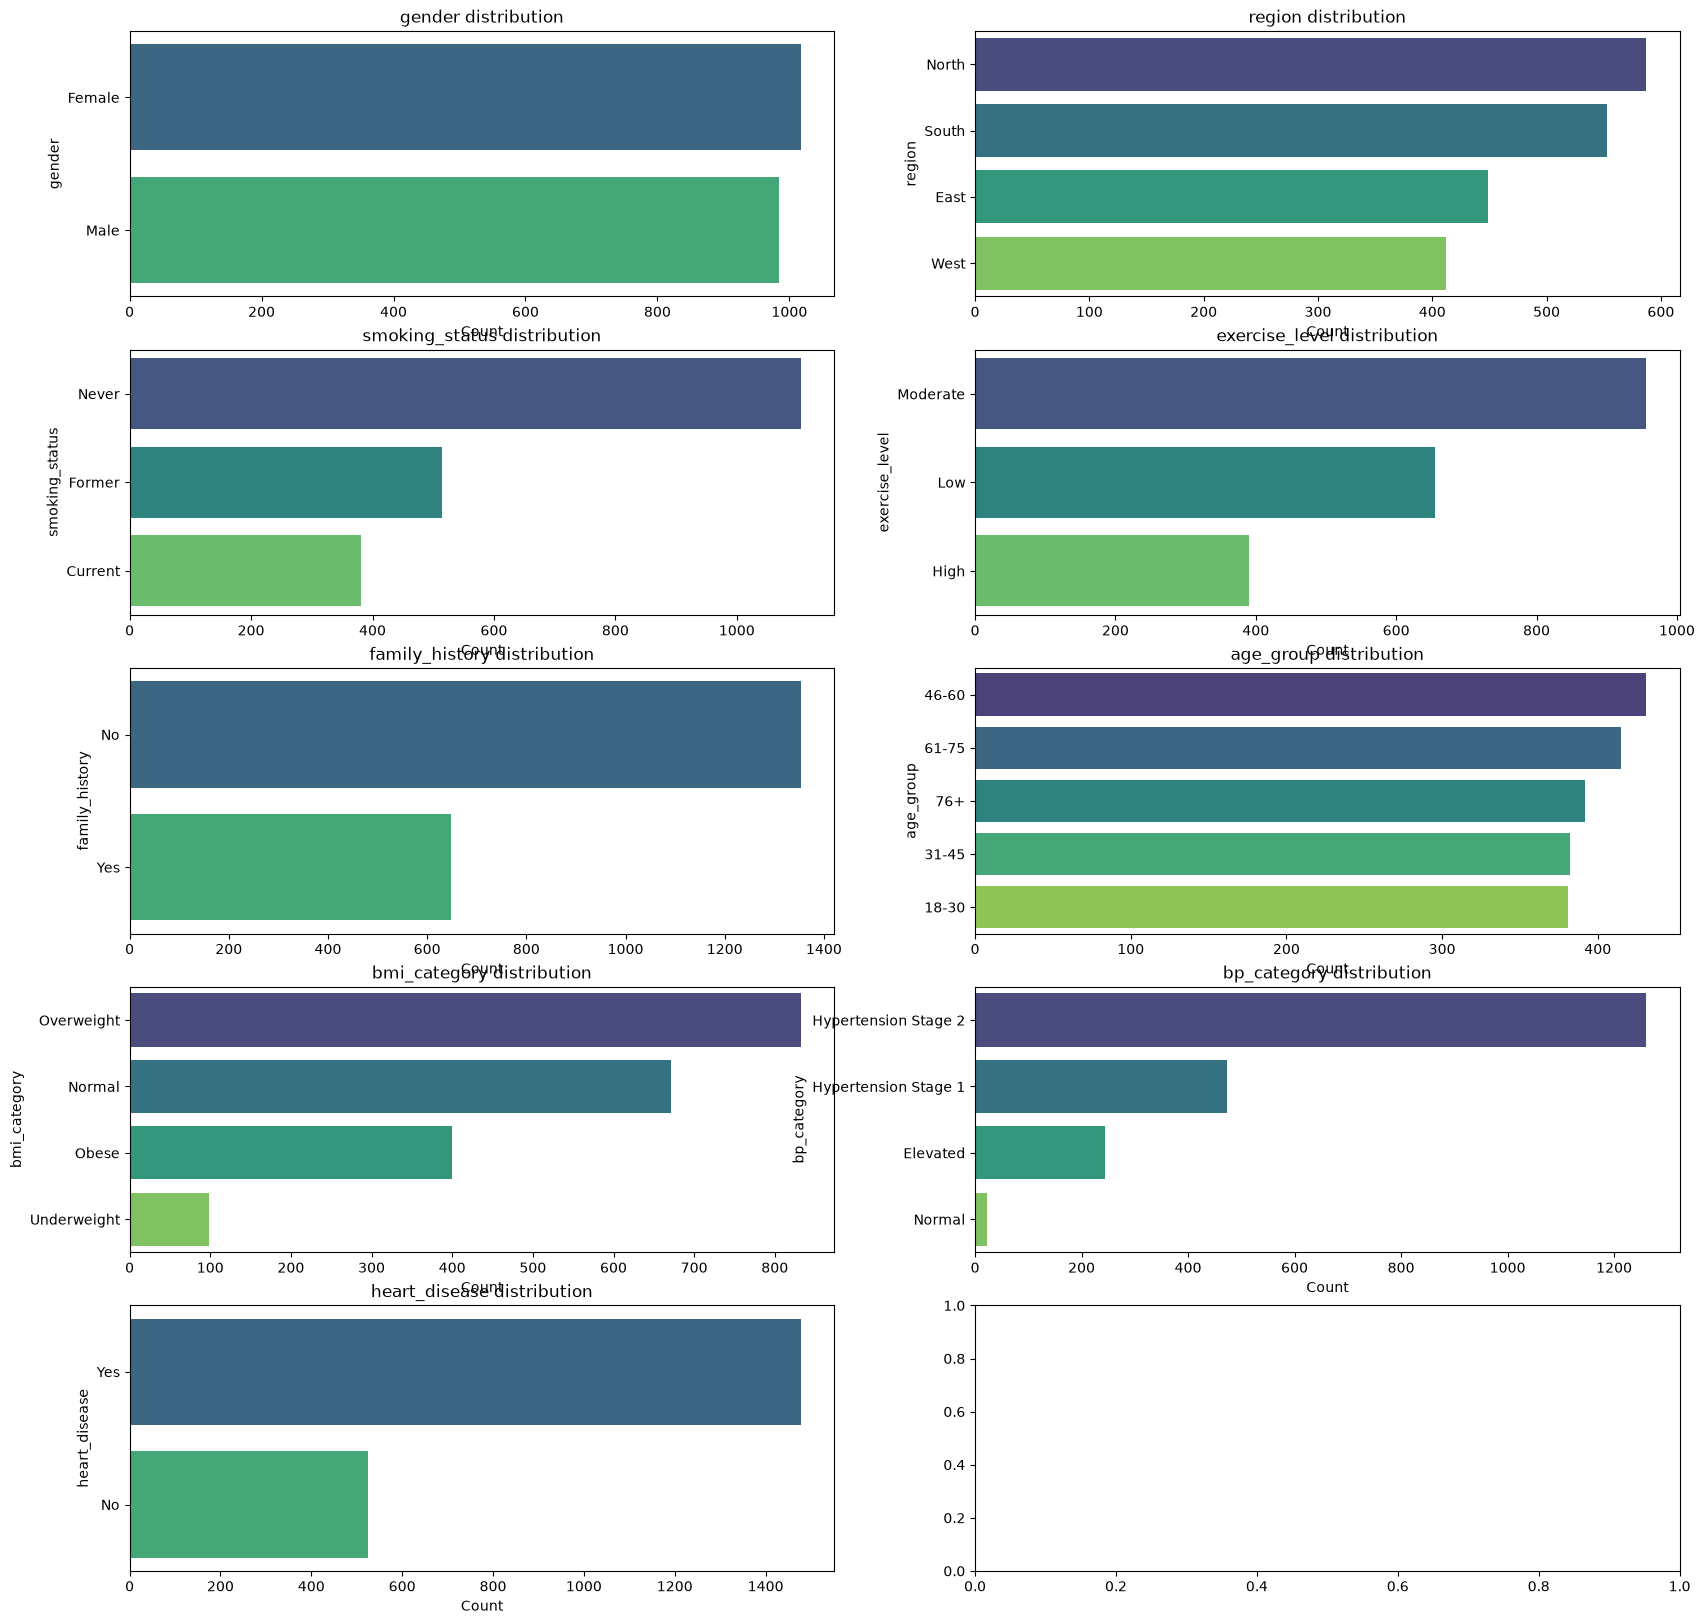

In [66]:
cat_cols = ['gender', 'region', 'smoking_status',
            'exercise_level', 'family_history', 'age_group', 'bmi_category',
            'bp_category', 'heart_disease']

fig, axes = plt.subplots(5, 2, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    order = df[col].value_counts().index
    sns.countplot(y=df[col], order=order, ax=axes[i], palette='viridis')
    axes[i].set_title(f'{col} distribution')
    axes[i].set_xlabel('Count')


- 3. multivariate analysis

In [67]:
df.head(1)

,patient_id,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease,age_group,bmi_category,bp_category,heart_disease_flag
0,101028,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No,46-60,Underweight,Hypertension Stage 1,0


In [68]:
df.drop(columns=["patient_id"],inplace=True)

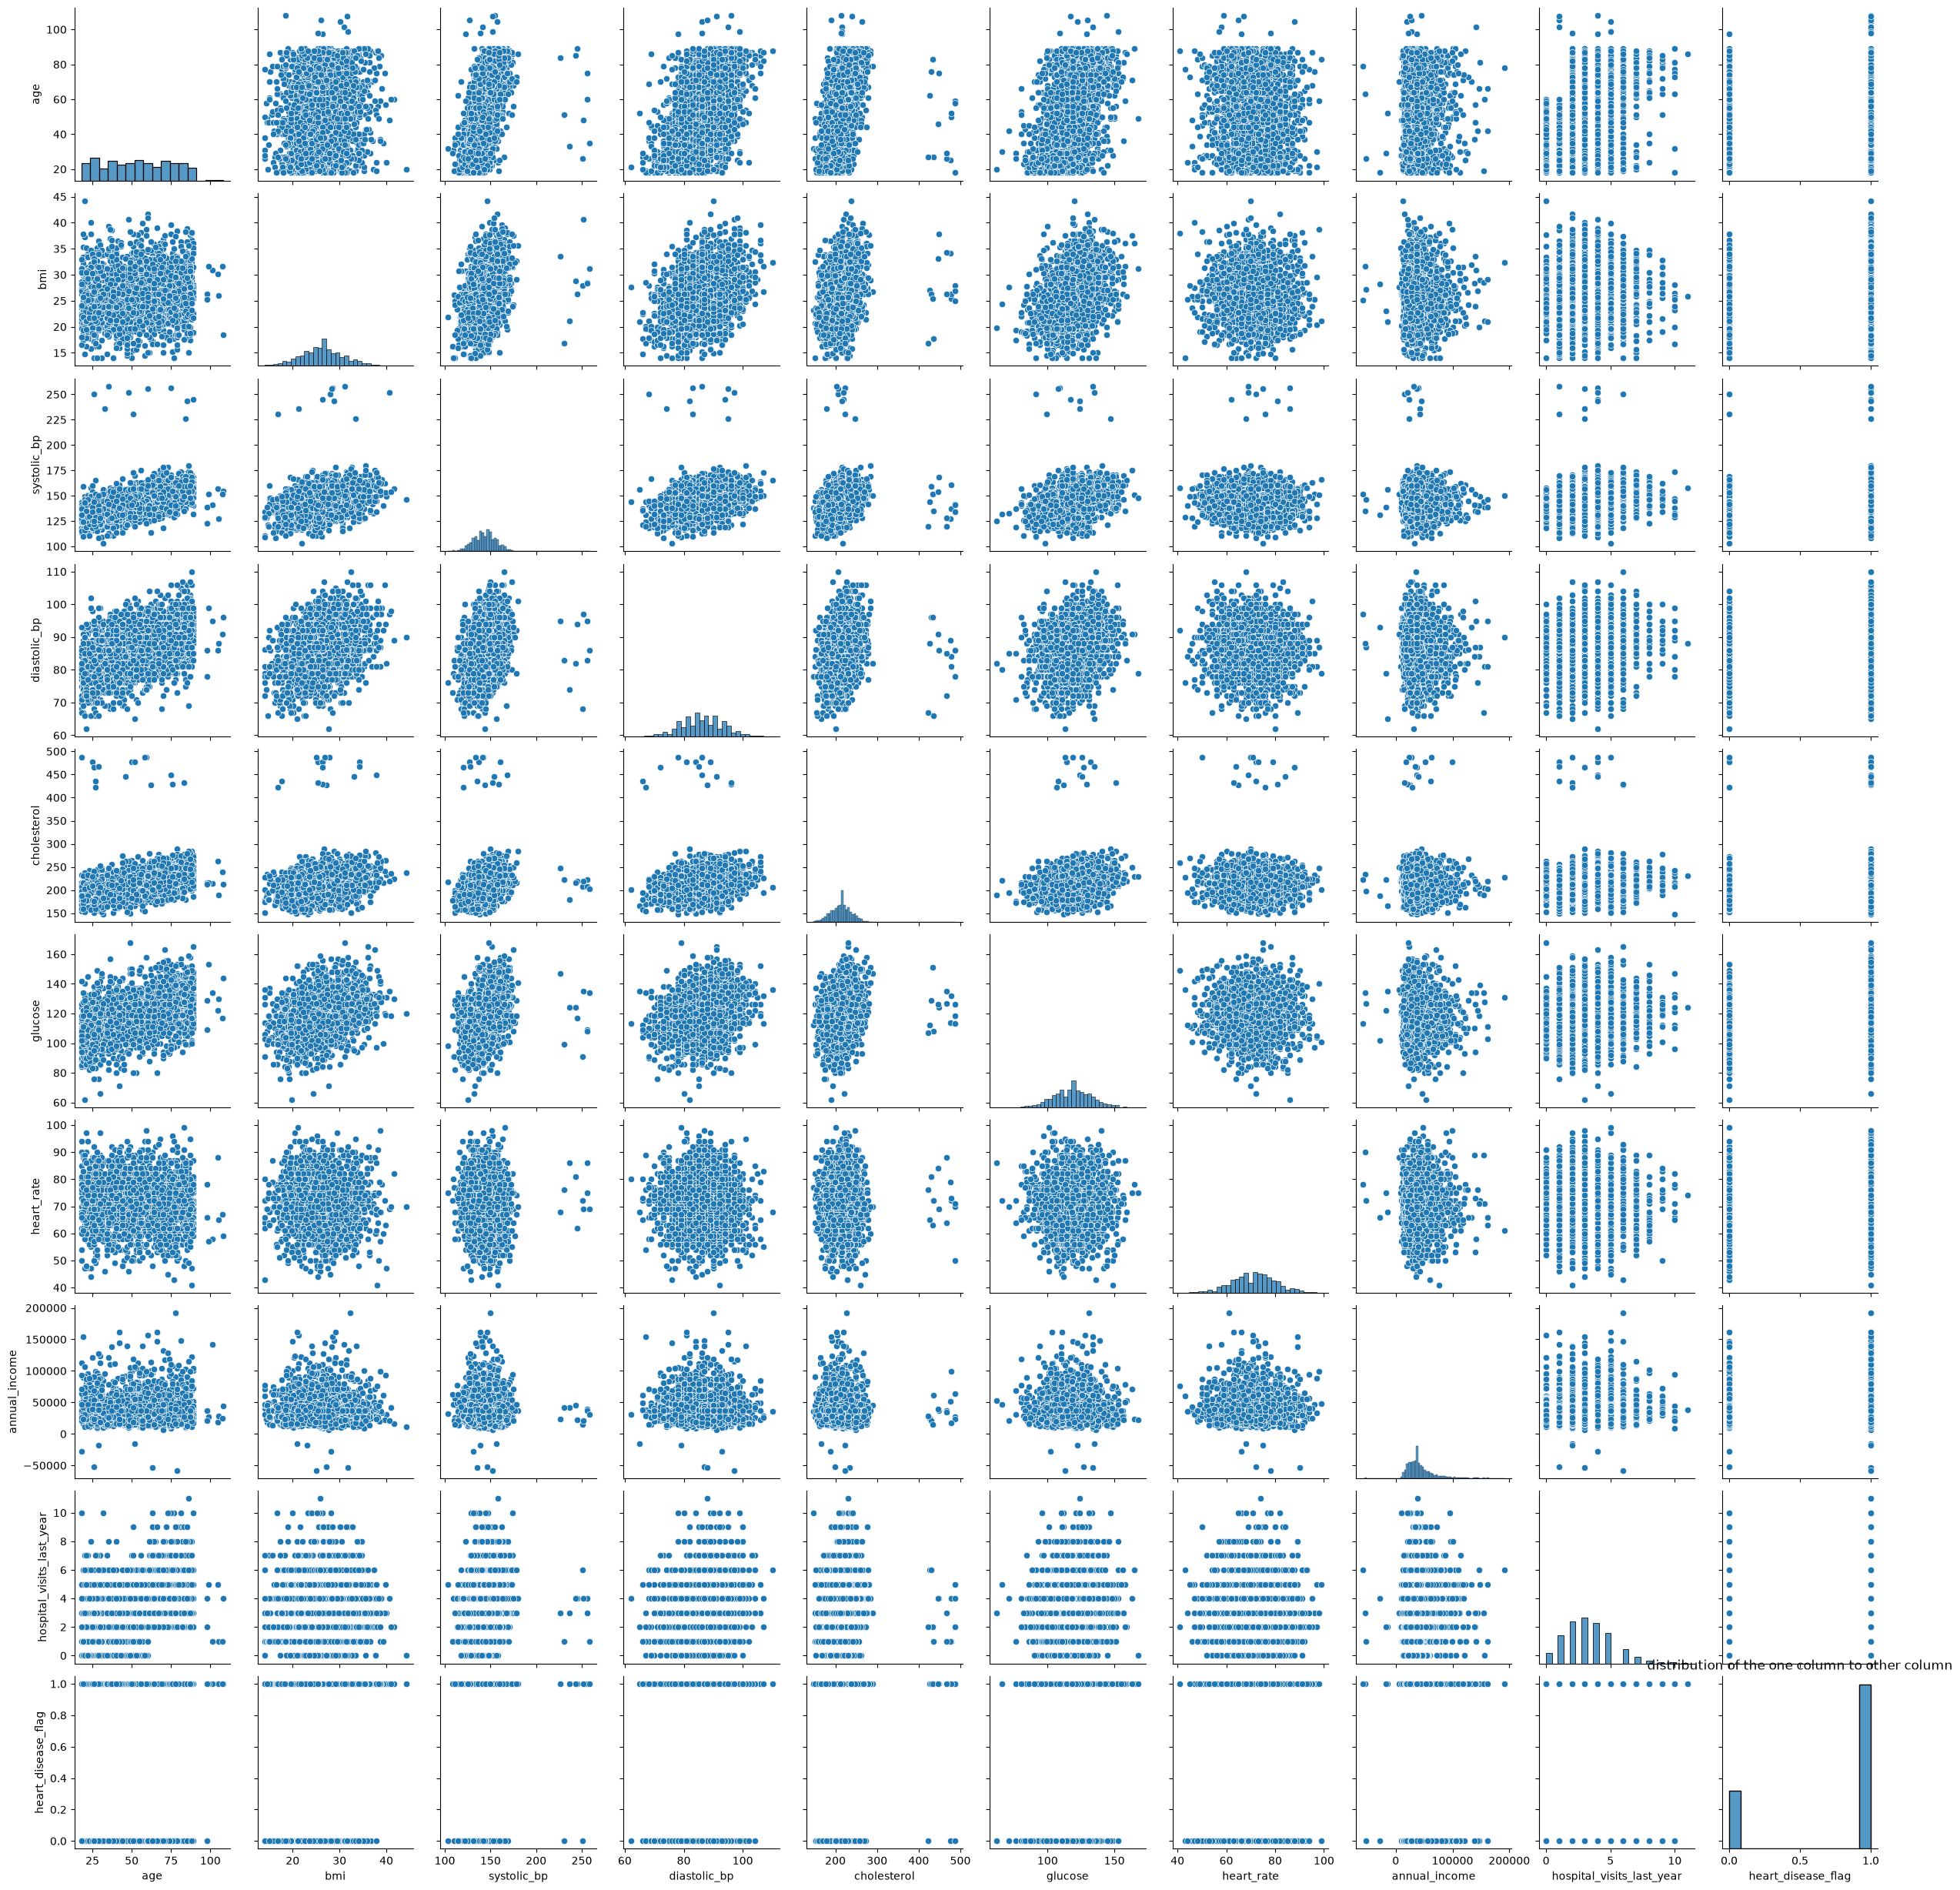

In [69]:
plt.Figure(figsize=(10,8))
sns.pairplot(df)
plt.title("distribution of the one column to other column")
plt.show()

In [70]:
df.head(1)

,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease,age_group,bmi_category,bp_category,heart_disease_flag
0,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No,46-60,Underweight,Hypertension Stage 1,0


In [71]:
df.corr(numeric_only=True)

,age,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,annual_income,hospital_visits_last_year,heart_disease_flag
age,1.000000,0.108144,0.546486,0.467398,0.360472,0.409802,-0.063088,0.016050,0.398420,0.372550
bmi,0.108144,1.000000,0.346985,0.352658,0.223242,0.304520,0.014657,-0.001653,0.026156,0.210971
systolic_bp,0.546486,0.346985,1.000000,0.338979,0.253727,0.300058,-0.021048,-0.021296,0.217746,0.303414
diastolic_bp,0.467398,0.352658,0.338979,1.000000,0.199087,0.263835,-0.034939,0.001072,0.166370,0.204640
cholesterol,0.360472,0.223242,0.253727,0.199087,1.000000,0.210442,-0.026480,-0.017165,0.140335,0.232157
glucose,0.409802,0.304520,0.300058,0.263835,0.210442,1.000000,-0.020411,-0.021292,0.149490,0.261610
heart_rate,-0.063088,0.014657,-0.021048,-0.034939,-0.026480,-0.020411,1.000000,-0.000856,-0.028264,0.004282
annual_income,0.016050,-0.001653,-0.021296,0.001072,-0.017165,-0.021292,-0.000856,1.000000,0.024563,-0.029647
hospital_visits_last_year,0.398420,0.026156,0.217746,0.166370,0.140335,0.149490,-0.028264,0.024563,1.000000,0.139290
heart_disease_flag,0.372550,0.210971,0.303414,0.204640,0.232157,0.261610,0.004282,-0.029647,0.139290,1.000000


<Axes: >

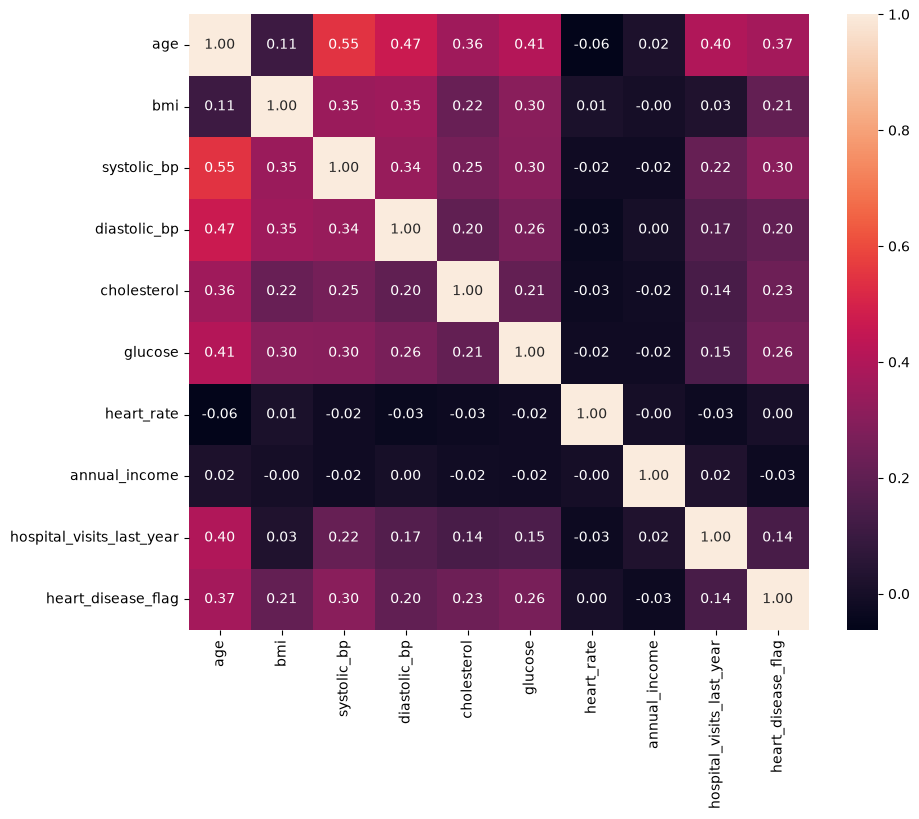

In [72]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True),fmt=".2f",annot=True)

- Finding outliers


- boxplot

In [73]:
df.head(1)

,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease,age_group,bmi_category,bp_category,heart_disease_flag
0,58.0,Female,North,16.4,133.0,83.0,172.0,106.0,78.0,Never,Moderate,No,37000.0,1,No,46-60,Underweight,Hypertension Stage 1,0


In [77]:
df.annual_income.value_counts()

annual_income
37300.0     164
34100.0      10
41000.0      10
37800.0      10
32700.0       9
           ... 
36500.0       1
59800.0       1
18200.0       1
39300.0       1
118800.0      1
Name: count, Length: 696, dtype: int64

- find outliers

In [78]:
Q1 = df['annual_income'].quantile(0.25)
Q3 = df['annual_income'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 27400.0
Q3: 49300.0
IQR: 21900.0
Lower Bound: -5450.0
Upper Bound: 82150.0


In [ ]:
# Display of outliers data

outliers = df[(df['annual_income'] < lower_bound) | 
              (df['annual_income'] > upper_bound)]

outliers[:5]

,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease,age_group,bmi_category,bp_category,heart_disease_flag
65,62.0,Female,South,28.8,151.0,87.0,241.000000,114.0,63.0,Never,Low,No,113900.0,5,Yes,61-75,Overweight,Hypertension Stage 2,1
116,50.0,Female,East,25.4,137.0,81.0,478.040948,114.0,72.0,Former,High,No,99400.0,1,No,46-60,Overweight,Hypertension Stage 1,0
128,79.0,Male,North,24.0,156.0,88.0,224.000000,125.0,72.0,Former,Moderate,No,105100.0,6,Yes,76+,Normal,Hypertension Stage 2,1
134,46.0,Male,West,26.6,142.0,79.0,249.000000,125.0,80.0,Former,Moderate,Yes,92000.0,2,Yes,46-60,Overweight,Hypertension Stage 2,1
145,88.0,Male,South,21.8,161.0,86.0,218.000000,118.0,78.0,Former,Moderate,No,122700.0,5,Yes,76+,Normal,Hypertension Stage 2,1


- remove outlers


In [83]:
df_clean = df[(df['annual_income'] >= lower_bound) & 
              (df['annual_income'] <= upper_bound)]

print("Original shape:", df.shape)
print("After removing outliers:", df_clean.shape)

Original shape: (2001, 19)
After removing outliers: (1884, 19)


In [84]:
Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 23.2
Q3: 29.2
IQR: 6.0
Lower Bound: 14.2
Upper Bound: 38.2


In [86]:
# Display of outliers data

outliers = df[(df['bmi'] < lower_bound) | 
              (df['bmi'] > upper_bound)]

outliers

,age,gender,region,bmi,systolic_bp,diastolic_bp,cholesterol,glucose,heart_rate,smoking_status,exercise_level,family_history,annual_income,hospital_visits_last_year,heart_disease,age_group,bmi_category,bp_category,heart_disease_flag
36,60.0,Female,South,41.7,157.000000,89.000000,225.0,130.000000,82.0,Never,Low,No,15800.0,2,Yes,46-60,Obese,Hypertension Stage 2,1
262,26.0,Female,East,14.0,134.000000,79.000000,179.0,106.000000,65.0,Current,High,No,41000.0,2,Yes,18-30,Underweight,Hypertension Stage 1,1
280,24.0,Female,North,40.0,149.000000,82.000000,232.0,131.000000,47.0,Never,Moderate,Yes,31500.0,3,Yes,18-30,Obese,Hypertension Stage 2,1
351,38.0,Male,North,14.0,128.000000,86.178259,201.0,103.000000,72.0,Current,Moderate,No,71400.0,1,No,31-45,Underweight,Elevated,0
354,38.0,Female,East,14.0,111.000000,81.000000,151.0,126.000000,64.0,Never,High,Yes,45200.0,3,No,31-45,Underweight,Elevated,0
689,37.0,Male,South,38.6,152.000000,81.000000,256.0,141.000000,57.0,Current,Moderate,No,36800.0,1,Yes,31-45,Obese,Hypertension Stage 2,1
797,75.0,Female,East,39.6,162.000000,106.000000,241.0,120.000000,72.0,Current,Low,No,22500.0,3,Yes,61-75,Obese,Hypertension Stage 2,1
830,66.0,Female,North,39.0,166.000000,99.000000,264.0,131.000000,78.0,Never,Low,No,33000.0,4,Yes,61-75,Obese,Hypertension Stage 2,1
859,31.0,Female,South,14.0,109.000000,79.000000,177.0,91.000000,80.0,Never,High,No,47000.0,4,Yes,31-45,Underweight,Normal,1
985,28.0,Male,North,14.0,134.000000,78.000000,174.0,114.000000,66.0,Never,Moderate,Yes,77500.0,0,No,18-30,Underweight,Hypertension Stage 1,0


In [87]:
df_clean = df[(df['bmi'] >= lower_bound) & 
              (df['bmi'] <= upper_bound)]

print("Original shape:", df.shape)
print("After removing outliers:", df_clean.shape)

Original shape: (2001, 19)
After removing outliers: (1978, 19)


- datainsights

everything about from starting to removing outliers

In [ ]:
# finding outliers for all numerical and removing outliers all numerical columns

import numpy as np

numerical_features = df.select_dtypes(include=np.number).columns

df_iqr = df.copy()

for col in numerical_features:
    Q1 = df_iqr[col].quantile(0.25)
    Q3 = df_iqr[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_iqr = df_iqr[
        (df_iqr[col] >= lower_bound) &
        (df_iqr[col] <= upper_bound)
    ]

print("Original shape:", df.shape)
print("After IQR:", df_iqr.shape)